# 01 — Train ONE model (template)

Choose the `CONFIG` in the parameters cell and run. Artifacts are saved
to `experiments/<model>__<timestamp>__<runid>/` on Drive.

## 1. Mount Google Drive and locate the project

⚠️ **Upload the ENTIRE PROJECT to Drive**, não só a pasta `Data`. A pasta
no Drive (por padrão `/content/drive/MyDrive/Fato_Tese_Ruido`) precisa conter:

```
Fato_Tese_Ruido/
├── requirements.txt
├── src/ftr/...        ← o módulo 'ftr' (sem isto: No module named 'ftr')
├── configs/
├── scripts/
└── Data/dataset_FINAL.json
```

The cell below **locates the project folder automatically** (by searching for
`src/ftr`) and shows a checklist of what is present or missing.

In [10]:
!nvidia-smi

Tue Jun  9 16:11:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P0             45W /  400W |       6MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [11]:
import os, sys, glob

# Mount Drive (Colab only).
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    IN_COLAB = False
    print('Not running on Colab — using local path.')


def _looks_like_project(p):
    return os.path.isdir(os.path.join(p, 'src', 'ftr'))


def _autodetect_root():
    candidates = ['/content/drive/MyDrive/Fato_Tese_Ruido']
    # search for any folder containing src/ftr inside MyDrive (2 levels)
    for base in ('/content/drive/MyDrive', '/content/drive/My Drive'):
        candidates += glob.glob(os.path.join(base, '**', 'src', 'ftr'), recursive=False)
        candidates += [os.path.dirname(os.path.dirname(p))
                       for p in glob.glob(os.path.join(base, '*', 'src', 'ftr'))]
    for c in candidates:
        if c and _looks_like_project(c):
            return c
    return candidates[0] if candidates else os.getcwd()


PROJECT_ROOT = _autodetect_root() if IN_COLAB else os.getcwd()
os.environ['FTR_PROJECT_ROOT'] = PROJECT_ROOT
if os.path.join(PROJECT_ROOT, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(PROJECT_ROOT, 'src'))
print('PROJECT_ROOT =', PROJECT_ROOT)

# Required items (code + data).
'src/ftr': 'folder (ftr module)', 'configs': 'folder',
            'scripts': 'folder', 'Data/dataset_FINAL.json': 'dataset'}
# Optional items (Drive sometimes converts .txt/.xlsx to Google Docs/Sheets,
# removing the extension — no problem, deps are installed explicitly below).
optional = {'requirements.txt': 'file (optional)'}
print('\nProject folder checklist:')
missing = []
for rel, kind in required.items():
    ok = os.path.exists(os.path.join(PROJECT_ROOT, rel))
    print(f'  [{"OK" if ok else "FALTA"}] {rel}  ({kind})')
    if not ok:
        missing.append(rel)
for rel, kind in optional.items():
    ok = os.path.exists(os.path.join(PROJECT_ROOT, rel))
    print(f'  [{"OK" if ok else "--"}] {rel}  ({kind})')
if missing:
    raise SystemExit('\nMISSING required items above. Upload the ENTIRE project folder to Drive (not just Data/).')
print('\nOK — all required items present. (requirements.txt is optional.)')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_ROOT = /content/drive/MyDrive/Fato_Tese_Ruido

Checklist da pasta do projeto:
  [OK] src/ftr  (pasta (módulo ftr))
  [OK] configs  (pasta)
  [OK] scripts  (pasta)
  [OK] Data/dataset_FINAL.json  (dataset)
  [--] requirements.txt  (arquivo (opcional))

OK — itens obrigatórios presentes. (requirements.txt é opcional.)


## 2. Install dependencies

Installs libraries explicitly (does not rely on `requirements.txt`, which Drive
sometimes converts to Google Docs format). torch is already available in Colab.

In [12]:
if IN_COLAB:
    !pip install -q 'transformers==4.48.3' 'datasets==3.3.0' 'scikit-learn==1.6.1' \
        evaluate sentencepiece sacremoses 'accelerate>=1.3.0' openpyxl seaborn pyarrow
    print('\nDependencies installed.')
else:
    print('Local: install with  pip install -r requirements.txt')


Dependências instaladas.


## 3. Check GPU, environment and paths

In [13]:
import torch
from ftr.env import describe_environment, get_paths
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
import json
print(json.dumps(describe_environment(), indent=2, ensure_ascii=False))

CUDA disponível: True
GPU: NVIDIA A100-SXM4-40GB
{
  "in_colab": true,
  "drive_mounted": true,
  "project_root": "/content/drive/MyDrive/Fato_Tese_Ruido",
  "root_exists": true,
  "raw_dataset": "/content/drive/MyDrive/Fato_Tese_Ruido/Data/dataset_FINAL.json",
  "raw_dataset_exists": true,
  "python": "3.12.13",
  "platform": "linux"
}


## 4. Check that the dataset is in place

In [14]:
paths = get_paths()
print('Raw dataset:', paths.raw_dataset)
assert paths.raw_dataset.exists(), (
    f'Dataset not found at {paths.raw_dataset}. '
    'Upload Data/dataset_FINAL.json to Drive.')
print('OK — dataset found (%.1f MB).' % (paths.raw_dataset.stat().st_size/1e6))

Dataset bruto: /content/drive/MyDrive/Fato_Tese_Ruido/Data/dataset_FINAL.json
OK — dataset encontrado (259.0 MB).


## 5. Experiment parameters

Available configs: `roberta_lexpt`, `roberta_crawlpt`, `bertimbau_large`,
`mbert`, `bertimbau_base`, `xlmr`, `mdeberta_v3`, `longformer_base`.

In [15]:
CONFIG = 'configs/longformer_base.yaml'  # @param
SMOKE_TEST = False  # @param  — True runs a quick smoke test (5 steps)
max_steps = 5 if SMOKE_TEST else None

## 6. Prepare data (if not done yet)

Includes **document-level split** (anti-leakage). If already run via `02_run_all_colab.ipynb`
this cell can be skipped — splits already exist.

In [16]:
from ftr.data import load_splits
splits = load_splits(paths.data_processed)
if 'train' not in splits:
    print('Preparing data (document-level split)...')
    !cd "{PROJECT_ROOT}" && python -W all scripts/01_prepare_data.py --config {CONFIG}
    splits = load_splits(paths.data_processed)
print('Splits:', {k: len(v) for k, v in splits.items()})

Splits: {'train': 20377, 'val': 2546, 'test': 2559}


In [19]:
cfg = load_config(CONFIG, configs_dir=paths.configs)
cfg["model"]["name"] = "allenai/longformer-base-4096"
cfg["experiment_id"] = "longformer_base"
print("model:", cfg["model"]["name"])  # confirm before running
status = train_experiment(cfg, paths, splits=splits, max_steps=max_steps)
print('Status:', status['status'], '| dir:', status['run_dir'])

2026-06-09 16:13:45,400 INFO === Iniciando experimento longformer_base (run eab2c197) ===
2026-06-09 16:13:45,425 INFO Tamanhos: {'train': 20377, 'val': 2546, 'test': 2559}


modelo: allenai/longformer-base-4096


config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

Epoch,Training Loss,Validation Loss,Accuracy,Balanced Accuracy,Mcc,Cohen Kappa,F1 Macro,F1 Micro,F1 Weighted,Precision Macro,Precision Weighted,Recall Macro,Recall Weighted,Roc Auc Macro Ovr,Pr Auc Macro,Log Loss,Brier Score Macro,F1 Tese,F1 Fato,F1 Ruido,Runtime,Samples Per Second,Steps Per Second
1,0.112600,0.137450,0.960723,0.959629,0.941244,0.940976,0.960301,0.960723,0.960666,0.961519,0.961151,0.959629,0.960723,0.995393,0.989718,0.137487,0.022098,0.938462,0.949451,0.992991,59.729400,42.626000,1.339000
2,0.072800,0.120686,0.968578,0.967445,0.953178,0.952773,0.968325,0.968578,0.968573,0.970018,0.969374,0.967445,0.968578,0.997675,0.995457,0.120675,0.018154,0.951094,0.956807,0.997074,59.143400,43.048000,1.353000
3,0.044200,0.116269,0.970935,0.969718,0.956745,0.956314,0.970593,0.970935,0.970879,0.972346,0.971692,0.969718,0.970935,0.998255,0.996659,0.116255,0.016988,0.952934,0.961181,0.997664,59.423300,42.845000,1.346000
4,0.056300,0.071911,0.979183,0.978857,0.968744,0.968737,0.978970,0.979183,0.979181,0.979098,0.979193,0.978857,0.979183,0.998874,0.997760,0.071898,0.011253,0.966646,0.973184,0.997081,59.484600,42.801000,1.345000
5,0.029900,0.069939,0.983111,0.982802,0.974646,0.974635,0.982949,0.983111,0.983105,0.983117,0.983122,0.982802,0.983111,0.999007,0.998031,0.069939,0.010030,0.972905,0.977108,0.998833,59.830700,42.553000,1.337000


Input ids are automatically padded to be a multiple of `config.attention_window`: 512
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Tr

Map:   0%|          | 0/2559 [00:00<?, ? examples/s]

2026-06-09 19:35:48,403 INFO === Concluído em 12123.0s ===


Status: completed | dir: longformer_base__20260609_161345__eab2c197


## 7. Train

In [20]:
# from ftr.config import load_config
# from ftr.train import train_experiment
# cfg = load_config(CONFIG, configs_dir=paths.configs)
# status = train_experiment(cfg, paths, splits=splits, max_steps=max_steps)
# print('Status:', status['status'], '| dir:', status['run_dir'])

## 8. View experiment metrics and charts

Accuracy : 0.9828
F1-macro : 0.9826
MCC      : 0.9742


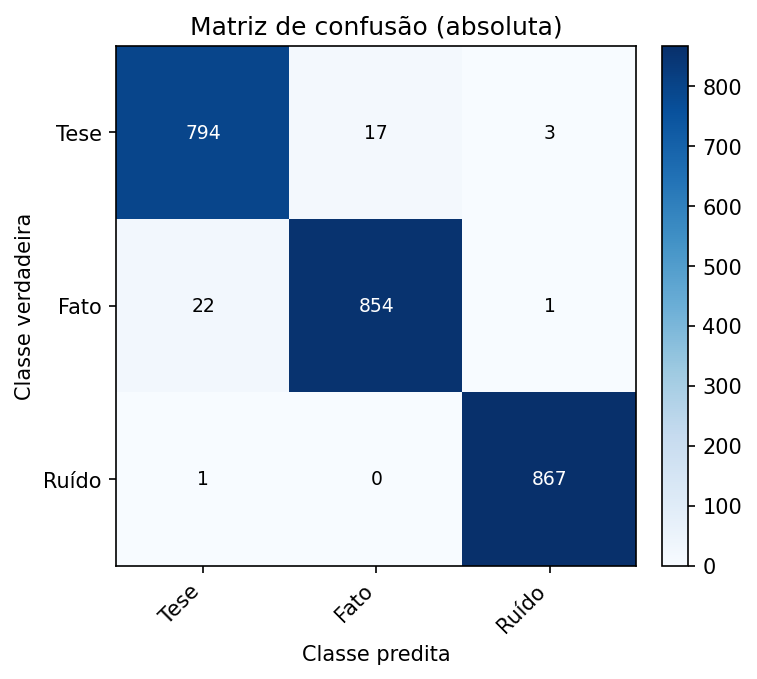

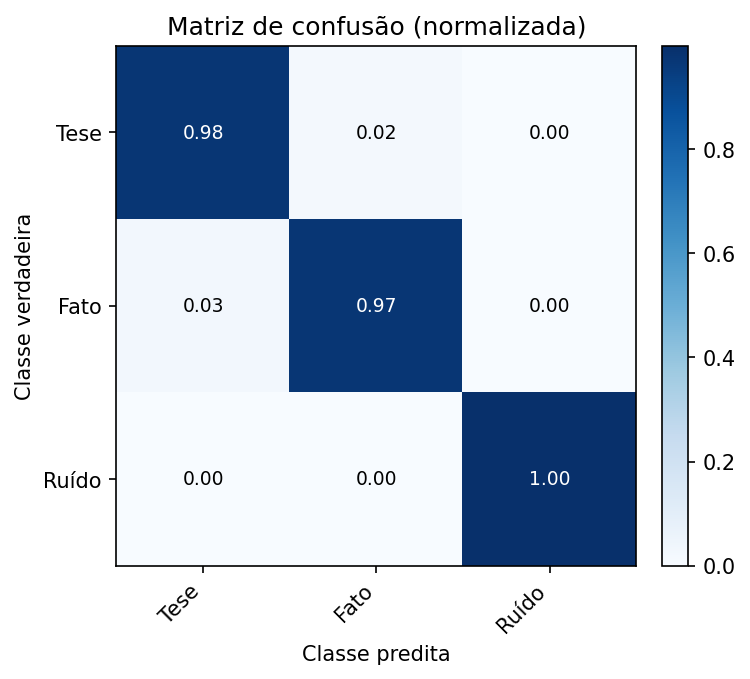

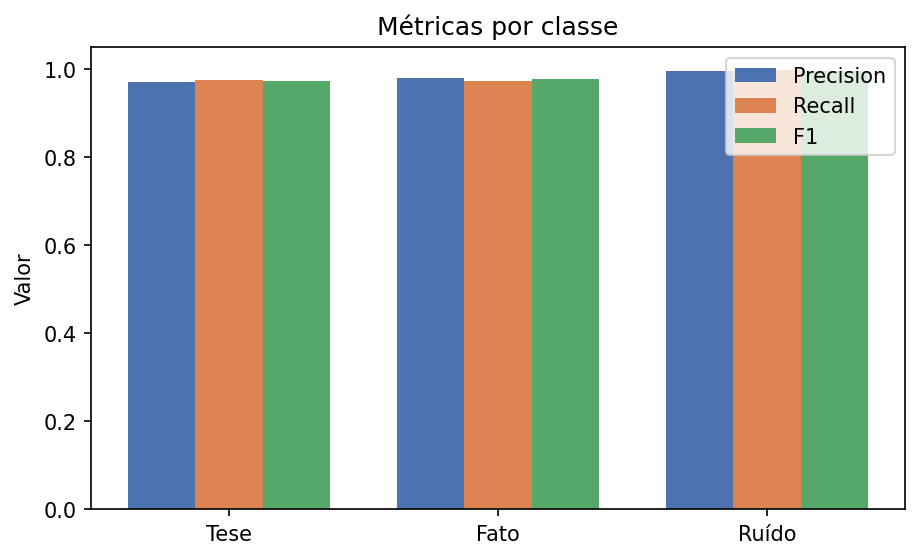

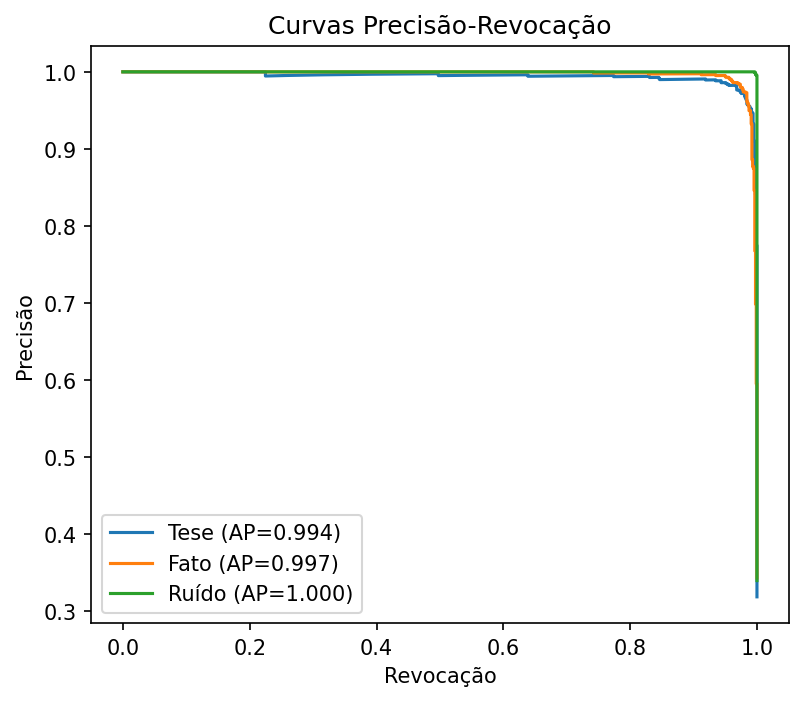

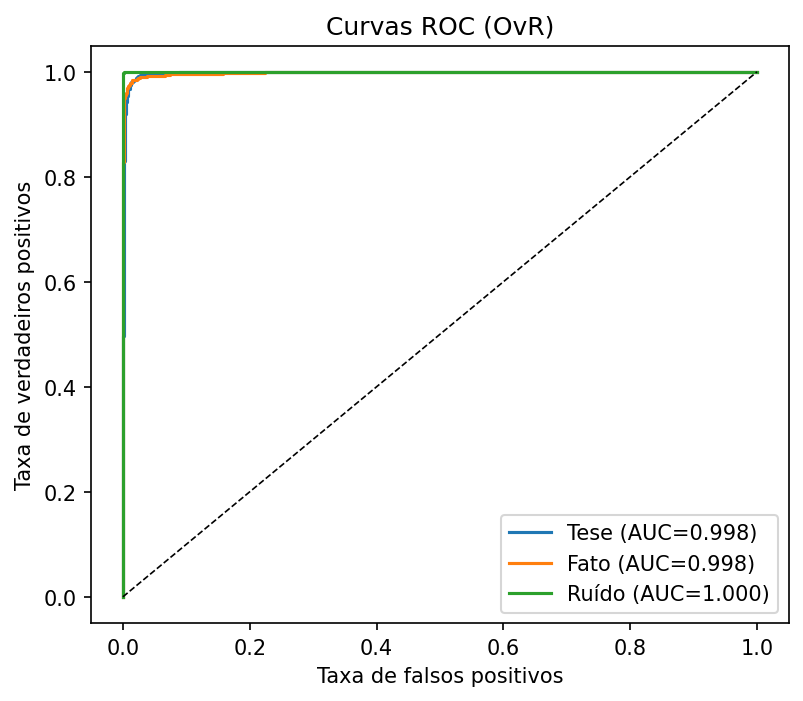

In [21]:
import json, glob
from IPython.display import Image, display
run_dir = paths.experiments / status['run_dir']
with open(run_dir / 'metrics' / 'test_metrics.json', encoding='utf-8') as f:
    m = json.load(f)
print('Accuracy :', round(m['accuracy'], 4))
print('F1-macro :', round(m['f1_macro'], 4))
print('MCC      :', round(m['mcc'], 4))
for fig in sorted(glob.glob(str(run_dir / 'figures' / '*_pt.png'))):
    display(Image(fig))